# 08 - EDA mối tương quan cryptocurrency và vĩ mô

**Câu hỏi:** lợi suất BTC theo tháng có liên hệ đồng thời với biến động tài sản/chỉ số vĩ mô hay không, và quan hệ đó có ổn định theo thời gian không?

**Cửa sổ chính:** `2018-01` đến tháng hoàn chỉnh gần nhất. Mốc 2018 được chọn trước khi xem kết quả để tập trung chế độ thị trường crypto hiện đại và có panel cân bằng 100 tháng; bảng sensitivity bắt đầu `2015-01` được xuất riêng để công khai phụ thuộc cửa sổ.

BTC/ETH dùng last-valid-price trong tháng. S&P 500 là thay đổi của mức price-level tháng theo nguồn (Shiller monthly-average trong phần lịch sử, FRED SP500 ở phần mở rộng mới) và vàng là thay đổi mức tháng theo nguồn; chúng không phải total return và không cùng convention timing hoàn toàn với BTC. VIX dùng thay đổi của trung bình tháng; lạm phát/lợi suất dùng thay đổi điểm phần trăm. Mức VIX chỉ dùng chia chế độ. Pearson/Spearman dùng pairwise complete, báo `n`, và p-value được hiệu chỉnh Benjamini-Hochberg cho family BTC-biến so sánh. Tương quan/hồi quy không chứng minh nhân quả.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sys.path.insert(0, str(Path.cwd() / "scripts"))
from common import TABLES, FIGURES, QUALITY, ensure_output_dirs, benjamini_hochberg, write_csv_atomic, write_json_atomic
ensure_output_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":120, "savefig.dpi":180, "font.family":"DejaVu Sans"})

data = pd.read_csv(TABLES / "analysis_crypto_macro_monthly.csv", parse_dates=["month"])
study = data.loc[data.month.between("2018-01-31", "2026-04-30")].copy()
variables = {
    "btc_return_pct":"BTC", "eth_return_pct":"ETH", "sp500_return_pct":"S&P 500",
    "gold_return_pct":"Vàng", "vix_change_pct":"Δ VIX", "dxy_return_pct":"DXY",
    "cpi_yoy_change_pp":"Δ lạm phát YoY", "us10y_change_pp":"Δ US10Y",
    "real_rate_change_pp":"Δ lãi suất thực", "brent_return_pct":"Dầu Brent",
}
matrix = study[["month", *variables]].rename(columns=variables)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
print(f"Cửa sổ chính: {study.month.min():%m/%Y}-{study.month.max():%m/%Y}; {len(study)} tháng lịch hoàn chỉnh")

Cửa sổ chính: 01/2018-04/2026; 100 tháng lịch hoàn chỉnh


## Kiểm định BTC với từng biến và hiệu chỉnh nhiều kiểm định

In [2]:
results = []
for column, label in variables.items():
    if column == "btc_return_pct": continue
    pair = study[["btc_return_pct", column]].dropna()
    pearson = stats.pearsonr(pair.btc_return_pct, pair[column])
    spearman = stats.spearmanr(pair.btc_return_pct, pair[column])
    results.append({
        "variable":label, "column":column, "n":len(pair),
        "pearson_r":float(pearson.statistic), "pearson_p_raw":float(pearson.pvalue),
        "spearman_rho":float(spearman.statistic), "spearman_p_raw":float(spearman.pvalue),
    })
correlation_tests = pd.DataFrame(results)
correlation_tests["pearson_q_bh"] = benjamini_hochberg(correlation_tests.pearson_p_raw)
correlation_tests["spearman_q_bh"] = benjamini_hochberg(correlation_tests.spearman_p_raw)
correlation_tests["pearson_significant_bh_5pct"] = correlation_tests.pearson_q_bh < .05
write_csv_atomic(correlation_tests, QUALITY / "eda_correlation_tests.csv")
correlation_tests.sort_values("pearson_p_raw")

,variable,column,n,pearson_r,pearson_p_raw,spearman_rho,spearman_p_raw,pearson_q_bh,spearman_q_bh,pearson_significant_bh_5pct
0,ETH,eth_return_pct,100,0.727043,1.087353e-17,0.757108,8.003469e-20,9.786179e-17,7.203122e-19,True
1,S&P 500,sp500_return_pct,100,0.200747,4.521249e-02,0.218974,2.860802e-02,2.034562e-01,1.287361e-01,False
3,Δ VIX,vix_change_pct,100,-0.182649,6.893250e-02,-0.201092,4.483682e-02,2.067975e-01,1.345105e-01,False
8,Dầu Brent,brent_return_pct,100,0.135365,1.793285e-01,0.083708,4.076625e-01,4.034891e-01,7.337925e-01,False
4,DXY,dxy_return_pct,100,-0.112715,2.641913e-01,-0.139730,1.655807e-01,4.755443e-01,3.725565e-01,False
2,Vàng,gold_return_pct,100,-0.079801,4.299717e-01,-0.044801,6.580580e-01,6.449575e-01,8.525446e-01,False
7,Δ lãi suất thực,real_rate_change_pp,98,0.032002,7.544200e-01,-0.019018,8.525446e-01,8.470239e-01,8.525446e-01,False
5,Δ lạm phát YoY,cpi_yoy_change_pp,98,-0.022834,8.234020e-01,0.029398,7.738439e-01,8.470239e-01,8.525446e-01,False
6,Δ US10Y,us10y_change_pp,100,0.019535,8.470239e-01,0.018856,8.522826e-01,8.470239e-01,8.525446e-01,False


## H11 - Ma trận tương quan của các biến đã biến đổi

**Vì sao dùng heatmap:** cần tổng hợp nhiều cặp biến định lượng trên cùng tần suất tháng.
Mỗi ô dùng pairwise-complete observations; bảng kiểm định riêng lưu `n`, p và q. Dấu sao chỉ
áp dụng cho quan hệ BTC với biến khác sau BH 5%, không gắn sao cho mọi cặp chưa kiểm định.

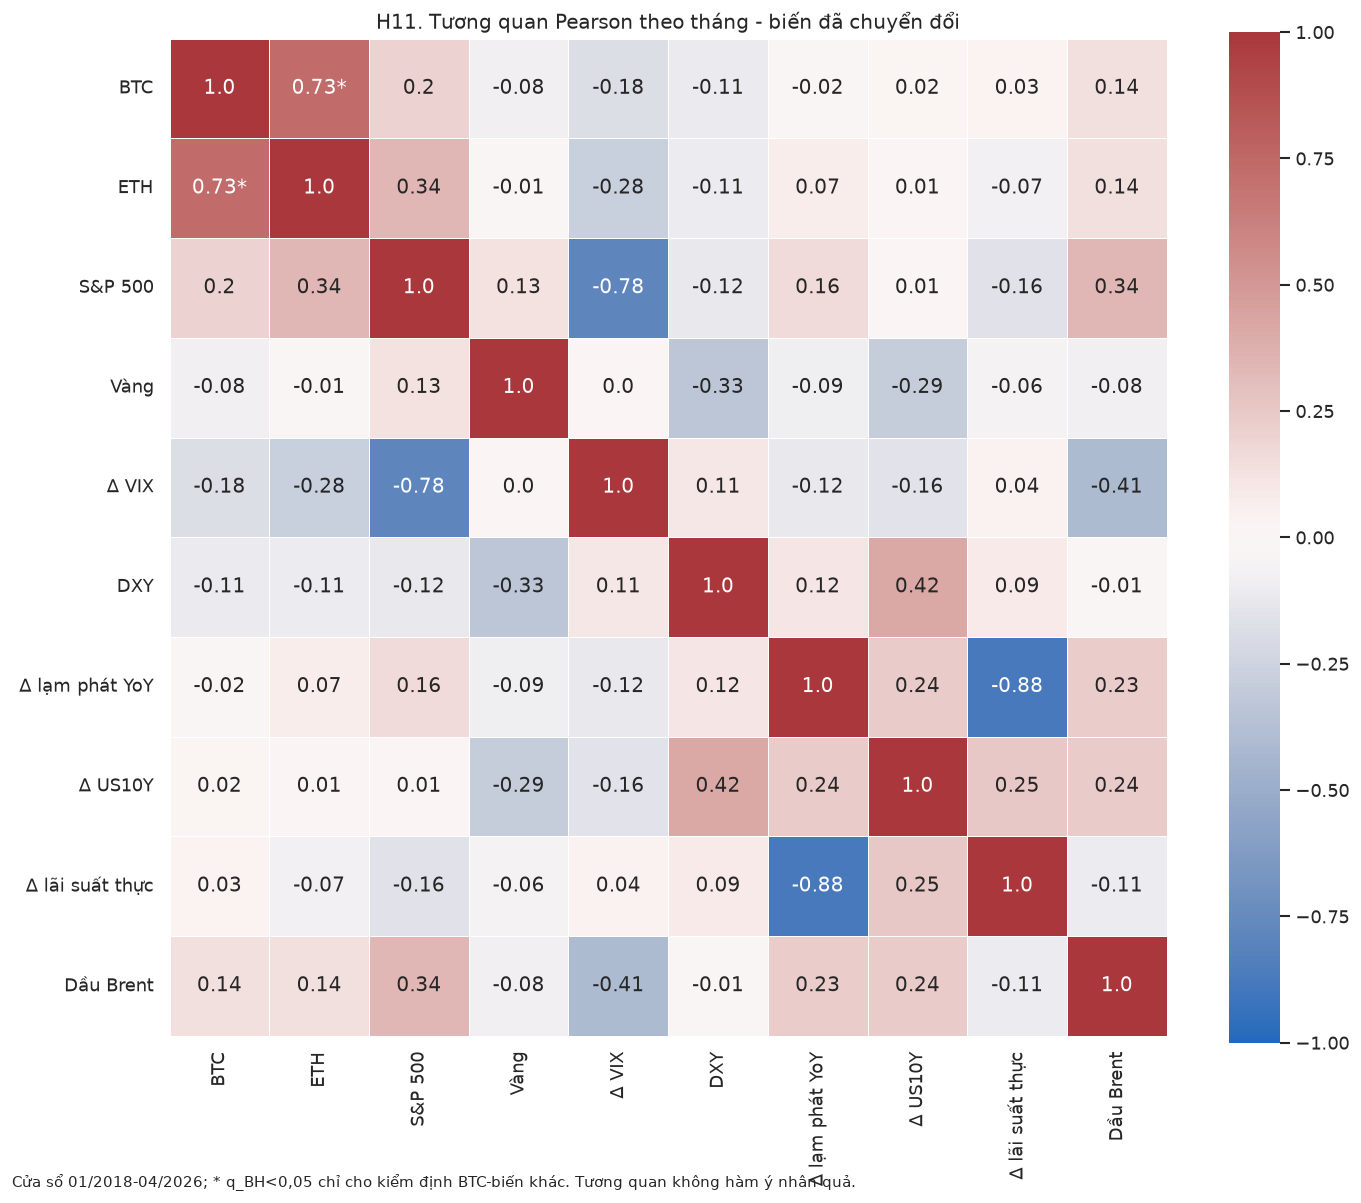

In [3]:
values = matrix.drop(columns="month")
corr = values.corr(method="pearson", min_periods=24)
labels = corr.round(2).astype(str)
sig = correlation_tests.set_index("variable").pearson_significant_bh_5pct
for variable, significant in sig.items():
    if significant and variable in labels.columns:
        labels.loc["BTC", variable] += "*"
        labels.loc[variable, "BTC"] += "*"
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=labels, fmt="", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax)
ax.set_title("H11. Tương quan Pearson theo tháng - biến đã chuyển đổi")
fig.text(.01, .01, "Cửa sổ 01/2018-04/2026; * q_BH<0,05 chỉ cho kiểm định BTC-biến khác. Tương quan không hàm ý nhân quả.", fontsize=9)
save(fig, "H11_heatmap_tuong_quan_thang.png")

## H12 - BTC và S&P 500 theo tháng

**Vì sao dùng scatter + hồi quy:** hai biến liên tục, mỗi điểm là một tháng; scatter cho thấy phân tán/outlier và đường OLS tóm tắt xu hướng tuyến tính. Sai số chuẩn HAC(3) giảm nhạy với phương sai thay đổi/tự tương quan ngắn. Trục x là thay đổi của **mức S&P 500 tháng theo nguồn**, không phải total return; trục y là lợi suất BTC last-valid-price trong tháng. Đây là mô tả đồng thời, không phải tác động nhân quả hay mô hình dự báo.

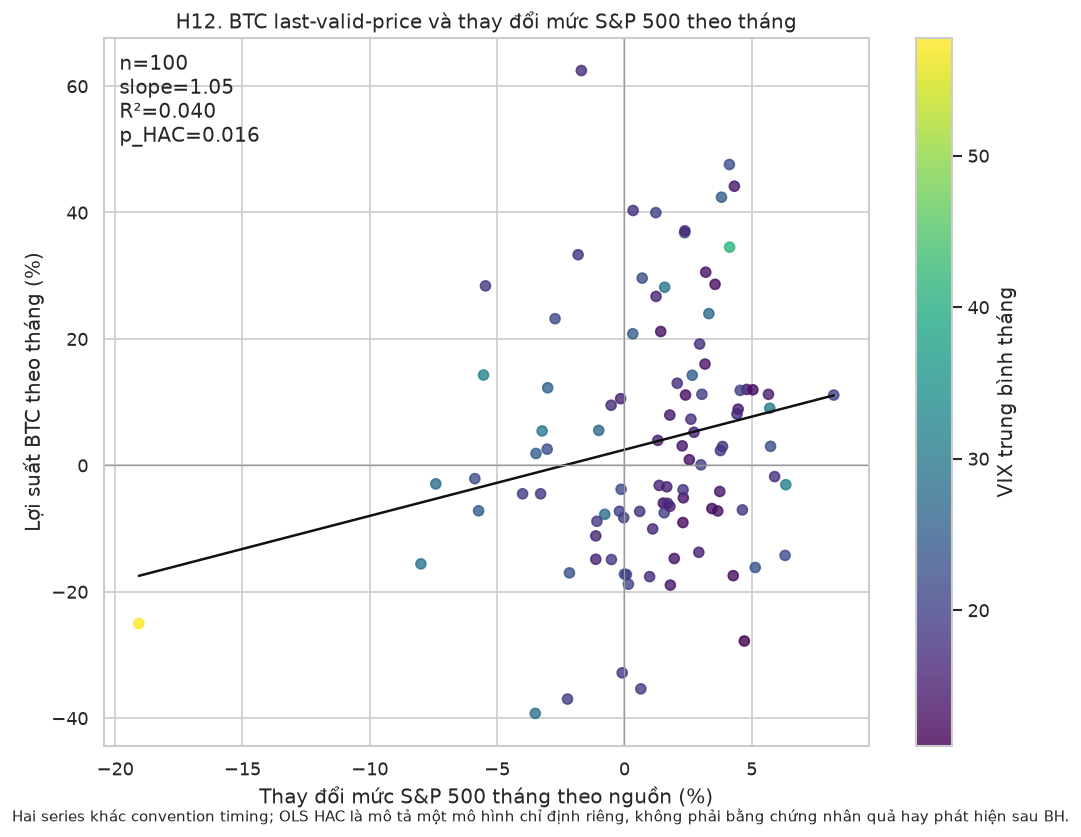

In [4]:
pair = study[["month", "btc_return_pct", "sp500_return_pct", "vix_mean"]].dropna()
X = sm.add_constant(pair["sp500_return_pct"])
model = sm.OLS(pair["btc_return_pct"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
xline = np.linspace(pair["sp500_return_pct"].min(), pair["sp500_return_pct"].max(), 200)
yline = model.params["const"] + model.params["sp500_return_pct"] * xline
fig, ax = plt.subplots(figsize=(9, 7))
scatter = ax.scatter(pair["sp500_return_pct"], pair["btc_return_pct"], c=pair["vix_mean"], cmap="viridis", alpha=.8)
ax.plot(xline, yline, color="#111111", linewidth=1.5)
ax.axhline(0, color="#999999", linewidth=.8); ax.axvline(0, color="#999999", linewidth=.8)
ax.set_title("H12. BTC last-valid-price và thay đổi mức S&P 500 theo tháng")
ax.set_xlabel("Thay đổi mức S&P 500 tháng theo nguồn (%)")
ax.set_ylabel("Lợi suất BTC theo tháng (%)")
fig.colorbar(scatter, ax=ax, label="VIX trung bình tháng")
ax.text(.02, .98, f"n={len(pair)}\nslope={model.params['sp500_return_pct']:.2f}\nR²={model.rsquared:.3f}\np_HAC={model.pvalues['sp500_return_pct']:.3f}", transform=ax.transAxes, va="top")
fig.text(.01, .01, "Hai series khác convention timing; OLS HAC là mô tả một mô hình chỉ định riêng, không phải bằng chứng nhân quả hay phát hiện sau BH.", fontsize=9)
save(fig, "H12_btc_vs_sp500.png")

## H13 - Tương quan trượt BTC-S&P 500

**Vì sao dùng rolling line:** một hệ số toàn mẫu có thể che giấu thay đổi theo thời gian. Cửa sổ 36 tháng, tối thiểu 24 cặp, ưu tiên độ ổn định nhưng vẫn quan sát được chuyển chế độ. Các cửa sổ chồng lấn chỉ dùng mô tả, không xem là kiểm định độc lập.

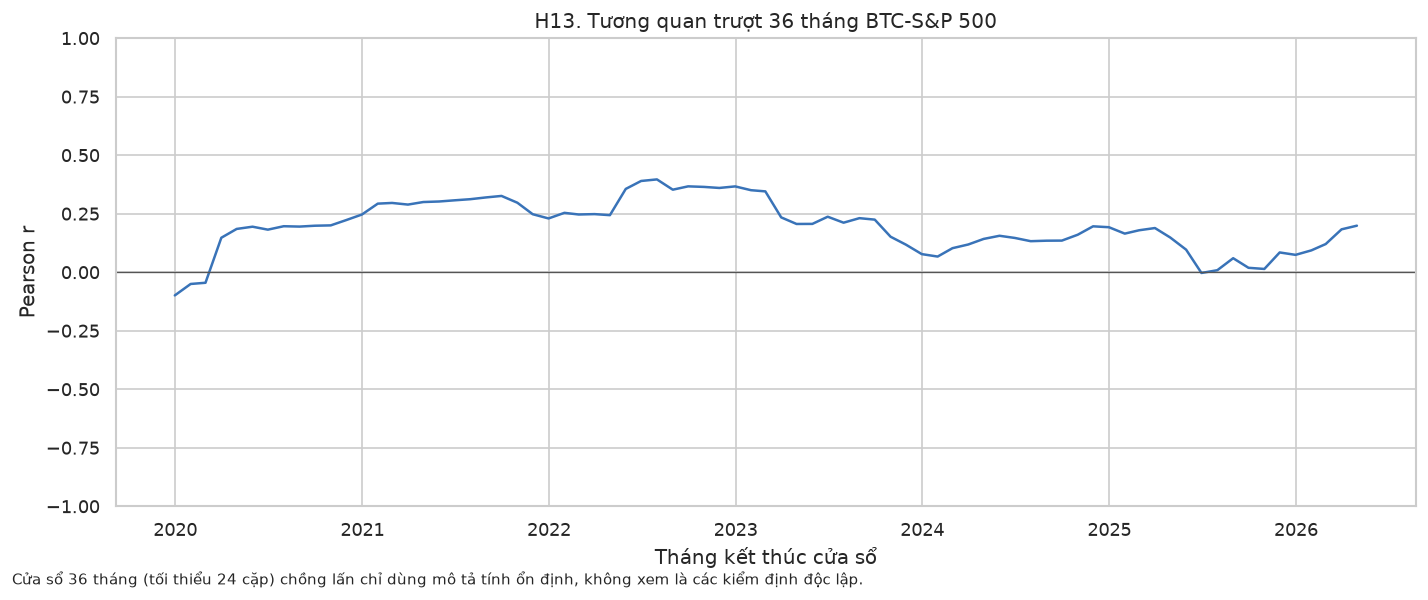

In [5]:
rolling = (
    study.set_index("month")[["btc_return_pct", "sp500_return_pct"]]
    .rolling(36, min_periods=24)
    .corr()
    .xs("btc_return_pct", level=1)["sp500_return_pct"]
)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(rolling.index, rolling, color="#3973B8")
ax.axhline(0, color="#555555", linewidth=.8)
ax.set_ylim(-1, 1); ax.set_title("H13. Tương quan trượt 36 tháng BTC-S&P 500")
ax.set_xlabel("Tháng kết thúc cửa sổ"); ax.set_ylabel("Pearson r")
fig.text(.01, .01, "Cửa sổ 36 tháng (tối thiểu 24 cặp) chồng lấn chỉ dùng mô tả tính ổn định, không xem là các kiểm định độc lập.", fontsize=9)
save(fig, "H13_rolling_corr_btc_sp500.png")

## H14 - Lợi suất BTC theo chế độ VIX

**Vì sao dùng box + điểm:** biến kết quả liên tục, chế độ rủi ro là phân loại. Boxplot cho
trung vị/IQR; điểm cho thấy cỡ mẫu và ngoại lệ. Phân nhóm dùng VIX trung bình cùng tháng nên
là mô tả đồng thời, không phải tín hiệu giao dịch biết trước.

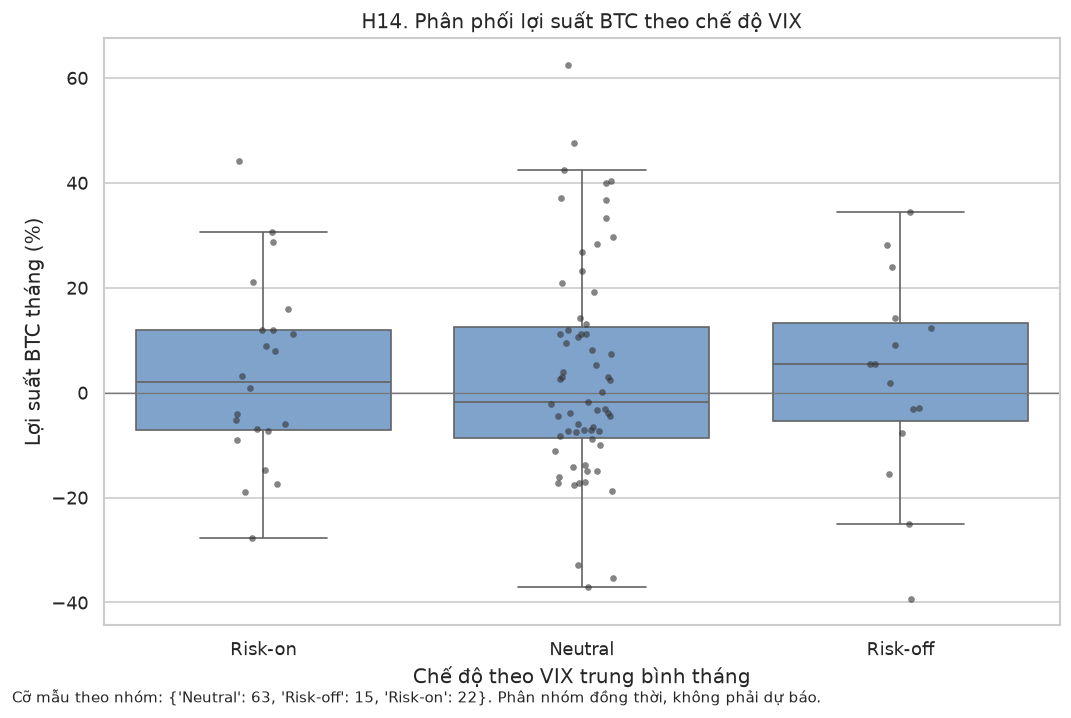

In [6]:
regime = study[["btc_return_pct","risk_regime"]].dropna().copy()
order = [x for x in ["Risk-on","Neutral","Risk-off"] if x in regime.risk_regime.unique()]
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=regime, x="risk_regime", y="btc_return_pct", order=order, showfliers=False, color="#73A2D6", ax=ax)
sns.stripplot(data=regime, x="risk_regime", y="btc_return_pct", order=order, color="#333333", alpha=.6, size=4, ax=ax)
ax.axhline(0,color="#777777",linewidth=.8)
ax.set_title("H14. Phân phối lợi suất BTC theo chế độ VIX")
ax.set_xlabel("Chế độ theo VIX trung bình tháng"); ax.set_ylabel("Lợi suất BTC tháng (%)")
counts = regime.groupby("risk_regime", observed=True).size().to_dict()
fig.text(.01, .01, f"Cỡ mẫu theo nhóm: {counts}. Phân nhóm đồng thời, không phải dự báo.", fontsize=9)
save(fig, "H14_btc_theo_vix_regime.png")

## Lưu kết quả thống kê có thể truy vết

In [7]:
regression = {
    "window_start": str(study.month.min().date()),
    "window_end": str(study.month.max().date()),
    "n": int(len(pair)),
    "slope_sp500": float(model.params["sp500_return_pct"]),
    "intercept": float(model.params["const"]),
    "r_squared": float(model.rsquared),
    "p_hac_sp500": float(model.pvalues["sp500_return_pct"]),
    "hac_maxlags": 3,
    "sp500_measurement": "change in source monthly average price level; not total return",
    "interpretation_limit": "Contemporaneous descriptive association; not causal or predictive.",
}
write_json_atomic(regression, QUALITY / "eda_regression_btc_sp500.json")

sensitivity_rows = []
for window_name, start in [("2015_start", "2015-01-31"), ("2018_main", "2018-01-31")]:
    window = data.loc[data["month"].between(start, "2026-04-30")].copy()
    for column, label in variables.items():
        if column == "btc_return_pct":
            continue
        pair_window = window[["btc_return_pct", column]].dropna()
        if len(pair_window) < 3:
            continue
        test = stats.pearsonr(pair_window["btc_return_pct"], pair_window[column])
        sensitivity_rows.append(
            {
                "window": window_name, "start_month": start,
                "end_month": window["month"].max(), "variable": label,
                "column": column, "n": len(pair_window),
                "pearson_r": float(test.statistic), "pearson_p_raw": float(test.pvalue),
            }
        )
sensitivity = pd.DataFrame(sensitivity_rows)
write_csv_atomic(sensitivity, QUALITY / "eda_window_sensitivity.csv")
display(regression)
display(sensitivity)

{'window_start': '2018-01-31',
 'window_end': '2026-04-30',
 'n': 100,
 'slope_sp500': 1.046654193477944,
 'intercept': 2.4613688772105853,
 'r_squared': 0.040299553386700326,
 'p_hac_sp500': 0.016088416482571526,
 'hac_maxlags': 3,
 'sp500_measurement': 'change in source monthly average price level; not total return',
 'interpretation_limit': 'Contemporaneous descriptive association; not causal or predictive.'}

,window,start_month,end_month,variable,column,n,pearson_r,pearson_p_raw
0,2015_start,2015-01-31,2026-04-30,ETH,eth_return_pct,128,0.494591,2.959011e-09
1,2015_start,2015-01-31,2026-04-30,S&P 500,sp500_return_pct,136,0.201027,1.893908e-02
2,2015_start,2015-01-31,2026-04-30,Vàng,gold_return_pct,136,-0.126460,1.423616e-01
3,2015_start,2015-01-31,2026-04-30,Δ VIX,vix_change_pct,136,-0.180105,3.588970e-02
4,2015_start,2015-01-31,2026-04-30,DXY,dxy_return_pct,136,-0.127375,1.394760e-01
5,2015_start,2015-01-31,2026-04-30,Δ lạm phát YoY,cpi_yoy_change_pp,134,0.004134,9.621857e-01
6,2015_start,2015-01-31,2026-04-30,Δ US10Y,us10y_change_pp,136,0.041246,6.335269e-01
7,2015_start,2015-01-31,2026-04-30,Δ lãi suất thực,real_rate_change_pp,134,0.016453,8.503376e-01
8,2015_start,2015-01-31,2026-04-30,Dầu Brent,brent_return_pct,136,0.137713,1.098657e-01
9,2018_main,2018-01-31,2026-04-30,ETH,eth_return_pct,100,0.727043,1.087353e-17
